In [1]:
import re
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyopenms as oms
import shutil
import subprocess
import math
import getpass
from matchms.logging_functions import set_matchms_logger_level
from matchms import Spectrum
from matchms.similarity import CosineGreedy
from sklearn.metrics import r2_score


set_matchms_logger_level("ERROR")
pd.set_option('display.width', 2000) 

There are 3 things that are required to start the validation:
1. Single labels (post-processed Yucca labels)
2. Results of clustering (DIA datasets only)
3. Output of the commercial method for analysis of chromatographic data (to benchmark against)
4. (optional) DDA fragments (when available)

Results of another method that we want to benchmark against is dataset dependent. Below are all 4 in separate chunks: 
1. Matrix - suspects (MsDial) - DIA
2. Matrix - standards (MsDial) - DIA
3. FlourineID - standards (openMS) - DDA
4. Wastewater - suspects (mzMine) - DDA

In [82]:
# Matrix - suspects (MsDial)
task_name = 'Task024_suspFinal'

# Here are compounds identified by another method + their metadata (depends on the method)
msdial_results = pd.read_csv('/home/frz603/DSP/matrix_suspects/DK_2021_Secondary metabolites_POS.csv', header = 0, skiprows=4, low_memory=False)
print(f'Total no. of detected compounds: {len(msdial_results)}')
# Only including batch 3 in the comparison
ind = msdial_results.columns.str.contains('Batch3')
# Including metadata like RT, precursor mass, MS/MS spectrum, ...
ind[0:32] = [True] * 32
msdial_results = msdial_results.loc[:, ind]
# Subsetting to the list of compounds that are actually ID-ed by MsDial
msdial_results = msdial_results[(msdial_results['Fill %']>=0.8) & (msdial_results['Metabolite name']!='Unknown')].reset_index(drop = True)
print(f'No. of reliable compounds: {len(msdial_results)}')
# Subsetting to only those compounds that are comfirmed with MS2 instead of just MS1 matching
msdial_results = msdial_results[~msdial_results["Metabolite name"].str.contains("w/o MS2", na=False)].reset_index(drop = True)
print(f'No. of compounds with MS2 comfirmed ID: {len(msdial_results)}')

# Just for later analysis (I have them only for standards)
concentrations = None

# Getting final table in standard format to be used for further validation
metadata = msdial_results.iloc[:, np.r_[3, 2, 1, 4, 10, 12, 31]]
print(metadata)
metadata.columns = ['Compound', 'mz', 'RT', 'adduct', 'formula', 'inchikey', 'MS2']
metadata.loc[:, "RT"] = metadata["RT"] * 60
peak_heights = msdial_results.iloc[:, 32:].sort_index(axis=1)
chrom_method_results = pd.concat([metadata, peak_heights], axis=1)

# Parameters used for image creation
rt_range = [100,1100]
rt_bin_size = 0.73
rt_bins = np.arange(rt_range[0], rt_range[1]+rt_bin_size, rt_bin_size)
mass_tol = 0.1

# Selecting only compounds that are actually visible in terms of image RT range
chrom_method_results = chrom_method_results[chrom_method_results['RT']>=rt_range[0]].reset_index(drop = True)
print(f'No. of compounds in final selection: {len(chrom_method_results)}')

# QC file (for getting raw - more precise - MS2 values out and precursor mass)
qc_name = '/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/matrix_files/230523_Batch3_090.mzML'

# Clustering results
clusters = pd.read_csv(f'/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/clustering/sim14/L3_raw/clusters_k30/final_matches.csv', header = 0)


Total no. of detected compounds: 9934
No. of reliable compounds: 395
No. of compounds with MS2 comfirmed ID: 370
                                       Metabolite name  Average Mz  Average Rt(min) Adduct type      Formula                     INCHIKEY                                     MS/MS spectrum
0    (1E,4Z,6E)-5-hydroxy-1,7-bis(4-hydroxy-3-metho...   369.11676            2.706      [M+H]+     C21H20O6  ZIUSSTSXXLLKKK-KOBPDPAPSA-N  71.01299:45 71.06825:44 80.94823:25 82.96167:4...
1    (1S,4aS,7aR)-7-methyl-1-[(2S,3R,4S,5S,6R)-3,4,...   513.13721            8.041     [M+Na]+    C21H30O13  WDMQLCVSWBENIY-QZTRPTDZSA-N  57.03719:31 65.04235:29 70.1172:21 77.04204:68...
2    (1S,4aS,7aR)-7-methyl-1-[(2S,3R,4S,5S,6R)-3,4,...   513.17346           10.860     [M+Na]+    C21H30O13  WDMQLCVSWBENIY-QZTRPTDZSA-N  64.67132:46 69.8119:37 70.9652:30 72.94271:40 ...
3    (1S,4aS,7aR)-7-methyl-1-[(2S,3R,4S,5S,6R)-3,4,...   513.17371           11.612     [M+Na]+    C21H30O13  WDMQLCVSWBENIY-QZTRPT

In [20]:
# Matrix - standards (MsDial)
task_name = 'Task024_standNeg'

# Importing compounds - there are two tables (one with all possible compounds that are expected in the leaf, the other with actual results), I'm matching between to include only subset that Ewa confirmed
compounds_detected = pd.read_excel('/home/frz603/DSP/matrix_standards/Standards_NEG.xlsx', skiprows = 4, header = 0)
all_compounds = pd.read_excel("/home/frz603/DSP/matrix_standards/Matrix_LCMS_Suspect Screening List final.xlsx", sheet_name="SSList_NEG")
flavonoids = all_compounds.loc[all_compounds['Class']=='Flavonoids', 'INCHIKEY'].to_numpy()  # only including flavonoids out of other secondary metabolites
compounds_detected = compounds_detected.loc[compounds_detected['INCHIKEY'].isin(flavonoids),:].reset_index(drop = True)
# I will subset to only compounds with perc of filled NA values that is less than 20%
compounds_detected = compounds_detected[compounds_detected['Fill %']>=0.7].reset_index(drop = True)

# I'm extracting only useful info out of the big table
metadata = compounds_detected.iloc[:, np.r_[3, 2, 1, 4, 10, 12, 31]]
metadata.columns = ['Compound', 'mz', 'RT', 'adduct', 'formula', 'inchikey', 'MS2']
metadata.loc[:, "RT"] = metadata["RT"] * 60
peak_heights = compounds_detected.iloc[:, 32:].sort_index(axis=1)
chrom_method_results = pd.concat([metadata, peak_heights], axis=1)

# I'm getting concentrations as reported by the chemist
concentrations = pd.read_excel('/home/frz603/DSP/matrix_standards/Standards_NEG.xlsx', nrows = 5, header = None).iloc[0, 32:].to_numpy()
concentrations = [0] + [float(x.replace('Cal_', '').replace('ppm', '')) for x in concentrations[1:]]  # first file in the sequence was a blank, hence 0 as concentration value

# Parameters used for image creation
rt_range = [100,1100]
rt_bin_size = 0.73
rt_bins = np.arange(rt_range[0], rt_range[1]+rt_bin_size, rt_bin_size)
mass_tol = 0.1

# Making sure that all compounds are within visible RT range in comparison to images
chrom_method_results = chrom_method_results[chrom_method_results['RT']>=rt_range[0]].reset_index(drop = True)
print(chrom_method_results)

# QC file (for getting raw - more precise - MS2 values out and precursor mass)
qc_name = '/home/frz603/DSP/matrix_standards/mzml_files/Negative/230503_Batch2_13.mzML'

# DDA fragments
dda_frag = pd.read_csv('/home/frz603/DSP/matrix_standards/dda/dda_matches.csv', header = 0)

# Clustering results
clusters = pd.read_excel(f'/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/clustering/sim14/L3_raw/clusters_k30/final_matches.xlsx', header = 0)


                        Compound         mz       RT  adduct    formula                     inchikey                                                MS2  230503_Batch2_06  230503_Batch2_13  230503_Batch2_14  230503_Batch2_15  230503_Batch2_16  230503_Batch2_17  230503_Batch2_18  230503_Batch2_19
0                       Apigenin  269.04593  1057.50  [M-H]-   C15H10O5  KZNIFHPLKGYRTM-UHFFFAOYSA-N  117.03476:6301 149.0238:1043 151.00272:887 159...                 0            683929            876643            419139            156652            106380             19374              2923
1                     Naringenin  271.06168   708.54  [M-H]-   C15H12O5  FTVWIRXFELQLPI-ZDUSSCGKSA-N  65.00267:2184 83.01344:2046 93.03375:2071 99.9...                 0           1119788            853938            435599            157402             72453             14711                 0
2                     Naringenin  271.06180  1017.84  [M-H]-   C15H12O5  FTVWIRXFELQLPI-ZDUSSCGKSA-N  65.00342:2

In [87]:
# Wastewater - DDA
task_name = 'Task026_wastewater'

# raw files
mzml_path = '/home/frz603/DSP/wastewater/mzml_files'
# raw files
mzml_files = sorted(os.listdir(mzml_path))

# comparison method results
compounds_all = pd.read_csv('/home/frz603/DSP/wastewater/aligned_features_extracted_0903.csv', header = 0)
compounds_detected = compounds_all[~compounds_all['Annotations'].isna()].reset_index(drop = True)
compounds_detected = compounds_detected.iloc[:, 1:]
compounds_detected = compounds_detected.rename(columns={
    'Annotations': 'Compound',
    'Confirmed by stantard': 'formula'
})
compounds_detected['RT'] = compounds_detected['RT']*60
# Add info on adducts
compounds_detected["adduct"] = np.nan
# Empty column for MS2 - DDA
compounds_detected["MS2"] = np.nan
# Empty column for inchikey - DDA
compounds_detected["inchikey"] = np.nan
# Add missing Blank1.mzML column filled with NA
compounds_detected["Blank1.mzML"] = np.nan
# Remove extra column
compounds_detected = compounds_detected.drop(columns=["T3IN1_2.mzML"], errors="ignore")
# Reorder again according to mzml_files
mzml_cols_ordered = [col for col in mzml_files if col in compounds_detected.columns]
other_cols = [col for col in compounds_detected.columns if col not in mzml_cols_ordered]

# Final table to use for comparison
chrom_method_results = compounds_detected[other_cols + mzml_cols_ordered]

# Parameters
rt_range = [0, 1000]
rt_bin_size = 0.45
rt_bins = np.arange(rt_range[0], rt_range[1]+rt_bin_size, rt_bin_size)

# QC file (for getting raw - more precise - MS2 values out and precursor mass)
qc_name = '/home/frz603/DSP/wastewater/mzml_files/QC.mzML'

In [2]:
# Flourine ID - DDA
task_name = 'Task025_standFlourID'

# raw files
mzml_path = '/home/frz603/DSP/mixes/mzml files/DDA'

# quick look at metadata for using raw data later
mix = [f.split('_')[1] for f in sorted(os.listdir(mzml_path))]
conc = [int(f.split('_')[2]) if f.split('_')[2].isnumeric() else None for f in sorted(os.listdir(mzml_path))]
metadata = pd.DataFrame({'file': sorted(os.listdir(mzml_path)), 'mix': mix, 'concentration': conc})

# Compounds identified by openMS
compounds_detected = pd.read_excel('/home/frz603/DSP/mixes/PM1-5-FluoroMix_50_ugL_pos_RTs_CUR_filtered.xlsx', header = 0)

# Compounds on the list of standards
compound_undetected = pd.read_excel('/home/frz603/DSP/mixes/qnts_mixes.xlsx', header = 0)
cols = ["name", "molecular_formula", "exact_mass", "rt_min", "mix", "conc"]
compound_undetected = compound_undetected[cols].copy()
compound_undetected = compound_undetected.rename(columns={
    'exact_mass': 'mz',
    'name': 'Compound',
    'molecular_formula': 'formula',
    'rt_min': 'RT',
    'mix': 'mix_cur'
})

# Parameters used for the specific dataset
rt_range = [0,1260]
rt_bin_size = 0.68
rt_bins = np.arange(rt_range[0], rt_range[1]+rt_bin_size, rt_bin_size)

# Concentrations
concentrations = [int(f.split('_')[2]) if f.split('_')[2].isnumeric() else None for f in sorted(os.listdir(mzml_path))]

# Each compound was present in only one mix (3 different concentrantions)
mix =  [f.split('_')[1] for f in sorted(os.listdir(mzml_path))]

# Just putting relevant info together
cols = ["Name", "Formula", "m/z", "Peak area", "RT (s)", "mix_cur"]
chrom_method_results = compounds_detected[cols].copy()
chrom_method_results = chrom_method_results.rename(columns={
    'm/z': 'mz',
    'Name': 'Compound',
    'Formula': 'formula',
    'RT (s)': 'RT'
})
chrom_method_results['adduct'] = np.nan

# Making it into a format I can work with
mzml_files = sorted(os.listdir(mzml_path))
for f in mzml_files:
    chrom_method_results["_".join(f.split("_")[:3])] = np.nan

# Adding info on the peak heigth (I have it only for one concentration - I guess 50)
for i in range(len(chrom_method_results)):
    col = [file_mix for file_mix in chrom_method_results.columns[7:] if (file_mix.split('_')[1] == chrom_method_results['mix_cur'].iloc[i]) & (file_mix.split('_')[2] == '50')] 
    if col:
        chrom_method_results.loc[i, col] = chrom_method_results['Peak area'].iloc[i]

# Adding necessary info into undetected compounds_detected
compound_undetected = compound_undetected[~compound_undetected['Compound'].isin(chrom_method_results['Compound'])].reset_index(drop = True)
compound_undetected['RT'] = compound_undetected['RT']*60
compound_undetected['mz'] = compound_undetected['mz'] + 1.0073  # positive mode
compound_undetected['adduct'] = '[M+H]+'

chrom_method_results

,Compound,formula,mz,Peak area,RT,mix_cur,adduct,003_Blank_MeOH,007_PM1_5,008_PM1_10,...,025_PM4_10,026_PM4_50,027_QC_PM1,028_Blank_MeOH,031_PM5_5,032_PM5_10,033_PM5_50,036_FluoroMix_5,037_FluoroMix_10,038_FluoroMix_50
0,Methamidophos,C2H8NO2PS,142.0086,41465070,137.14,PM1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fenuron,C9H12N2O,165.1022,124974284,335.33,PM1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Metolcarb,C9H11NO2,166.0863,1429456,443.27,PM1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Allidochlor,C8H12ClNO,174.0680,13425003,435.91,PM1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fuberidazole,C11H8N2O,185.0709,282136417,262.92,PM1,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
562,5-Fluorocytosine,C4H4FN3O,130.0411,22015255,49.30,FluoroMix,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22015255.0
563,Citalopram hydrobromide,C20H21FN2O,325.1711,205873912,433.44,FluoroMix,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,205873912.0
564,Lansoprazole,C16H14F3N3O2S,370.0832,35324038,414.13,FluoroMix,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35324038.0
565,Dexamethasone,C22H29FO5,393.2072,18859778,473.96,FluoroMix,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18859778.0


In [21]:
# Importing results of clustering - dataset specific
version = 'sim13'

# Single labels - postprocessed Yucca labels
single_labels_path = f'/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/clustering/{version}/L3_raw/single_labels_overlap'

# Info on extracted labels
ms1_files = [f for f in os.listdir(single_labels_path) if "MS1_" in f]
ms2_files = [f for f in os.listdir(single_labels_path) if "MS2_" in f]

print(f"Found {len(ms1_files)} MS1 files")
print(f"Found {len(ms2_files)} MS2 files")

FileNotFoundError: [Errno 2] No such file or directory: '/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/Task024_standNeg/clustering/sim13/L3_raw/single_labels_overlap'

In [3]:
# ONLY for Flourine ID
qc_files = [f for f in sorted(os.listdir(mzml_path)) if f.split('_')[2] == '50']

# Here is raw spectra for MS1 for all mixes (file with highest concentration)
df_ms1 = pd.DataFrame()

for qc_name in qc_files:

    print(qc_name)

    exp = oms.MSExperiment()
    oms.MzMLFile().load(os.path.join(mzml_path, qc_name), exp)

    df_file = exp.get_df(long=True)
    df_file = df_file[df_file['ms_level']==1]
    df_file["file"] = qc_name
    df_file["mix"] = qc_name.split('_')[1]

    df_ms1 = pd.concat([df_ms1, df_file], ignore_index=True)

df_ms1

009_PM1_50_ugL_pos_dda_5_inj.mzML
014_PM2_50_ugL_pos_dda_5_inj.mzML
021_PM3_50_ugL_pos_dda_5_inj.mzML
026_PM4_50_ugL_pos_dda_5_inj26.mzML
033_PM5_50_ugL_pos_dda_5_inj.mzML
038_FluoroMix_50_ugL_pos_dda_5_inj.mzML


,RT,mz,inty,ms_level,file,mix
0,0.085133,90.006752,17827.226562,1,009_PM1_50_ugL_pos_dda_5_inj.mzML,PM1
1,0.085133,90.008194,28148.355469,1,009_PM1_50_ugL_pos_dda_5_inj.mzML,PM1
2,0.085133,90.054703,51728.847656,1,009_PM1_50_ugL_pos_dda_5_inj.mzML,PM1
3,0.085133,90.062805,7189.618164,1,009_PM1_50_ugL_pos_dda_5_inj.mzML,PM1
4,0.085133,90.506729,47856.804688,1,009_PM1_50_ugL_pos_dda_5_inj.mzML,PM1
...,...,...,...,...,...,...
18342231,1259.768433,1167.841675,4030.794189,1,038_FluoroMix_50_ugL_pos_dda_5_inj.mzML,FluoroMix
18342232,1259.768433,1175.449463,3848.686523,1,038_FluoroMix_50_ugL_pos_dda_5_inj.mzML,FluoroMix
18342233,1259.768433,1179.902832,4348.020020,1,038_FluoroMix_50_ugL_pos_dda_5_inj.mzML,FluoroMix
18342234,1259.768433,1199.319336,4419.119629,1,038_FluoroMix_50_ugL_pos_dda_5_inj.mzML,FluoroMix


In [13]:
# Importing raw data from QC file (for more precise m/z in MS1 and MS2)
exp = oms.MSExperiment()  # IMPORTANT: reset each loop
oms.MzMLFile().load(qc_name, exp)
df_file = exp.get_df(long=True)
df_ms1 = df_file[df_file['ms_level']==1]

# Uncomment for DIA
df_ms2 = df_file[df_file['ms_level']==2]

Calibration curve - for both DDA and DIA in MS1 across all samples


Standards are plotted against expected concentration levels (to compare both U-Net and another method to expected values), but suspects are only plotted against another method

In [15]:
# Creating a table for comparison between UNet and another method (and/or expected concentrations)
comparison_table = pd.DataFrame()
compound_info = pd.DataFrame()
not_matched = pd.DataFrame()

n_comp = len(chrom_method_results)
n_matched = 0
#n_comp = 5

for i in range(n_comp):

    expected_mz = chrom_method_results['mz'].iloc[i]
    expected_rt = chrom_method_results['RT'].iloc[i]
    reported_int = chrom_method_results.iloc[i, 7:].to_numpy()
    adduct = chrom_method_results['adduct'].iloc[i]
   
    print(f'Compound #{i}: {chrom_method_results['Compound'].iloc[i]} - m/z = {expected_mz}, RT = {expected_rt}')

    # Finding single labels with the same mass range
    all_labels = [
        f for f in os.listdir(single_labels_path)
        if (float(f.split('_')[2] + '.' + f.split('_')[3]) <= expected_mz) &
        (float(f.split('_')[4] + '.' + re.sub('.npy', '', f.split('_')[5])) >= expected_mz) &
        (f.split('_')[1] == 'MS1')
    ]

    #print(all_labels)

    matched = False
    
    # Now going through all selected labels to find one that matches in RT 

    for j in range(len(all_labels)):    
        img =  np.load(os.path.join(single_labels_path, all_labels[j]))
        # Single label has 0s everywhere expect in the peak region
        if (img>0).any():
            rt_ind= np.unique(np.where(img>0)[1])
            # Turning it back into real-life RT terms to compare with the compound expected RT
            rt_range = [rt_bins[np.min(rt_ind)], rt_bins[np.max(rt_ind)]]
            # Checking if expected RT is inside of the single label
            if (expected_rt>=rt_range[0]) & (expected_rt<=rt_range[1]):
                # getting max peak heights in the label
                single_label = all_labels[j]
                #print(single_label)
                mph = np.max(img, axis = 1)
                #reported_int = np.repeat(None, len(mph))
                # getting precise precursor m/z (max point in the mz_range x rt_range)
                mz_range = [float(single_label.split('_')[2]+'.'+single_label.split('_')[3]), float(single_label.split('_')[4]+'.'+single_label.split('_')[5])]
                n_matched = n_matched + 1
                # getting precursor info
                # only FlourineId
                #mass_slice = df_ms1[(df_ms1['mz']>=mz_range[0]) & (df_ms1['mz']<=mz_range[1]) & (df_ms1['RT']>=rt_range[0]) & (df_ms1['RT']<=rt_range[1]) & (df_ms1['mix']==chrom_method_results['mix_cur'].iloc[i])].reset_index(drop = True)
                mass_slice = df_ms1[(df_ms1['mz']>=mz_range[0]) & (df_ms1['mz']<=mz_range[1]) & (df_ms1['RT']>=rt_range[0]) & (df_ms1['RT']<=rt_range[1])].reset_index(drop = True)
                # general info on the compound
                if len(mass_slice) > 0:
                    matched = True
                    compound_info = pd.concat([compound_info, pd.DataFrame({'Compound': [chrom_method_results['Compound'].iloc[i]],
                                                                            'MS1 label': [single_label],
                                                                            'precursor mass': [mass_slice.loc[np.argmax(mass_slice['inty']), 'mz']],
                                                                            'precursor int': [np.max(mass_slice['inty'])],
                                                                            'expected mass': expected_mz,
                                                                            'mz min': [mz_range[0]], 
                                                                            'mz max': [mz_range[1]],
                                                                            'expected RT': expected_rt, 
                                                                            'RT min': [rt_range[0]],
                                                                            'RT max': [rt_range[1]],
                                                                            'inchikey':  [chrom_method_results['inchikey'].iloc[i]],
                                                                            'MsDial MS2': [chrom_method_results['MS2'].iloc[i]],
                                                                            'formula': [chrom_method_results['formula'].iloc[i]],
                                                                            'adduct': adduct})], ignore_index=True)
                                                                  
                    # calibration curve
                    comparison_table = pd.concat([comparison_table, pd.DataFrame({'Compound': chrom_method_results['Compound'].iloc[i], 
                                                                                'UNet height': mph,
                                                                                'Software height': reported_int,
                                                                                'Concentration': concentrations,
                                                                                #'mix': [chrom_method_results["mix_cur"].iloc[i] if f.split("_")[1] == chrom_method_results["mix_cur"].iloc[i] else np.nan for f in mzml_files],
                                                                                'MS1 label': single_label})], ignore_index=True)
        
    if not matched: not_matched = pd.concat([not_matched, chrom_method_results.iloc[[i]]], ignore_index=True)

#print(f'No. of compounds not matched: {len(not_matched)}/{n_comp}')
print(f'No. of compounds matched: {round(len(compound_info)/n_comp, 2)*100}% ({len(compound_info)}/{n_comp})')
print(f'No. of compounds matched: {round(n_matched/n_comp, 2)*100}%')


Compound #0: w/o MS2:Luteolin - m/z = 267.06699, RT = 530.4
Compound #1: w/o MS2:Apigenin - m/z = 269.00815, RT = 922.3199999999999
Compound #2: w/o MS2:Apigenin - m/z = 269.01346, RT = 670.0799999999999
Compound #3: Apigenin - m/z = 269.01398, RT = 1019.0999999999999
Compound #4: Apigenin - m/z = 269.04285, RT = 1019.34
Compound #5: Apigenin - m/z = 269.04501, RT = 342.6
Compound #6: Apigenin - m/z = 269.04547, RT = 563.1
Compound #7: Apigenin - m/z = 269.04593, RT = 1057.5
Compound #8: w/o MS2:Naringenin - m/z = 271.04129, RT = 227.28
Compound #9: w/o MS2:Naringenin - m/z = 271.04443, RT = 944.0999999999999
Compound #10: w/o MS2:Naringenin - m/z = 271.05054, RT = 854.94
Compound #11: Naringenin - m/z = 271.06168, RT = 708.54
Compound #12: w/o MS2:Naringenin - m/z = 271.06168, RT = 1074.1799999999998
Compound #13: Naringenin - m/z = 271.0618, RT = 1017.8399999999999
Compound #14: w/o MS2:Naringenin - m/z = 271.0975, RT = 564.3
Compound #15: Kaempferol - m/z = 285.0386, RT = 686.939999

In [19]:
not_matched

,Compound,mz,RT,adduct,formula,inchikey,MS2,230503_Batch2_06,230503_Batch2_13,230503_Batch2_14,230503_Batch2_15,230503_Batch2_16,230503_Batch2_17,230503_Batch2_18,230503_Batch2_19
0,Apigenin,269.01398,1019.10,[M-H]-,C15H10O5,KZNIFHPLKGYRTM-UHFFFAOYSA-N,65.00386:1788 83.01328:1225 93.03391:2435 107....,0,0,8645,8268,7671,6284,0,0
1,Apigenin,269.04285,1019.34,[M-H]-,C15H10O5,KZNIFHPLKGYRTM-UHFFFAOYSA-N,65.00319:811 83.01283:992 93.03426:449 107.013...,0,9208,0,0,0,0,0,0
2,w/o MS2:Naringenin,271.04129,227.28,[M-C6H8O6-H]-,C15H12O5,FTVWIRXFELQLPI-ZDUSSCGKSA-N,107.01341:1898 108.02124:6881 109.02798:3649 1...,0,2421,1911,0,0,0,0,0
3,w/o MS2:Naringenin,271.05054,854.94,[M-H]-,C15H12O5,FTVWIRXFELQLPI-ZDUSSCGKSA-N,147.892:1072,0,0,0,0,0,0,2836,2552
4,w/o MS2:Naringenin,271.06168,1074.18,[M-H]-,C15H12O5,FTVWIRXFELQLPI-ZDUSSCGKSA-N,117.03483:1244 119.05016:1257 148.03973:1095 1...,0,0,3734,0,0,2337,0,2261
5,w/o MS2:Kaempferol,285.03952,1158.42,[M-H]-,C15H10O6,IYRMWMYZSQPJKC-UHFFFAOYSA-N,119.04955:5733 133.06526:2352 134.07147:870 14...,0,16901,14688,10466,0,0,0,0
6,w/o MS2:kaempferol,285.07809,1097.04,[M-H]-,C15H10O6,IYRMWMYZSQPJKC-UHFFFAOYSA-N,119.04913:1862 159.8927:1167 171.98328:1464 18...,0,0,0,0,0,0,3489,2549
7,w/o MS2:Kaempferol,285.20758,1149.84,[M-H]-,C15H10O6,IYRMWMYZSQPJKC-UHFFFAOYSA-N,119.04947:12787 164.9866:1290 170.00371:2295 1...,0,3129,3038,0,0,0,3362,3455
8,w/o MS2:Quercitrin,445.07645,599.16,[M-C6H10O4-H]-,C21H20O11,OXGUCUVFOIWWQJ-HQBVPOQASA-N,143.08611:3361 145.10204:4500 157.0659:2301 16...,0,3504,2931,0,0,0,0,0
9,w/o MS2:Quercitrin,447.07675,599.70,[M-C6H8O6-H]-,C21H20O11,OXGUCUVFOIWWQJ-HQBVPOQASA-N,143.08611:3361 145.10204:4500 157.0659:2301 16...,0,28501,23603,11499,4240,0,0,0


In [12]:
compound_info.to_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/info_L3.xlsx", index=False)
comparison_table.to_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/calibration_curve_L3.xlsx", index=False)
not_matched.to_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/not_matched.xlsx", index=False)

In [ ]:
#compound_info = pd.read_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/info_L3.xlsx", header = 0)
#comparison_table = pd.read_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/calibration_curve_L3.xlsx", header = 0)
#not_matched = pd.read_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/not_matched.xlsx", header=0)

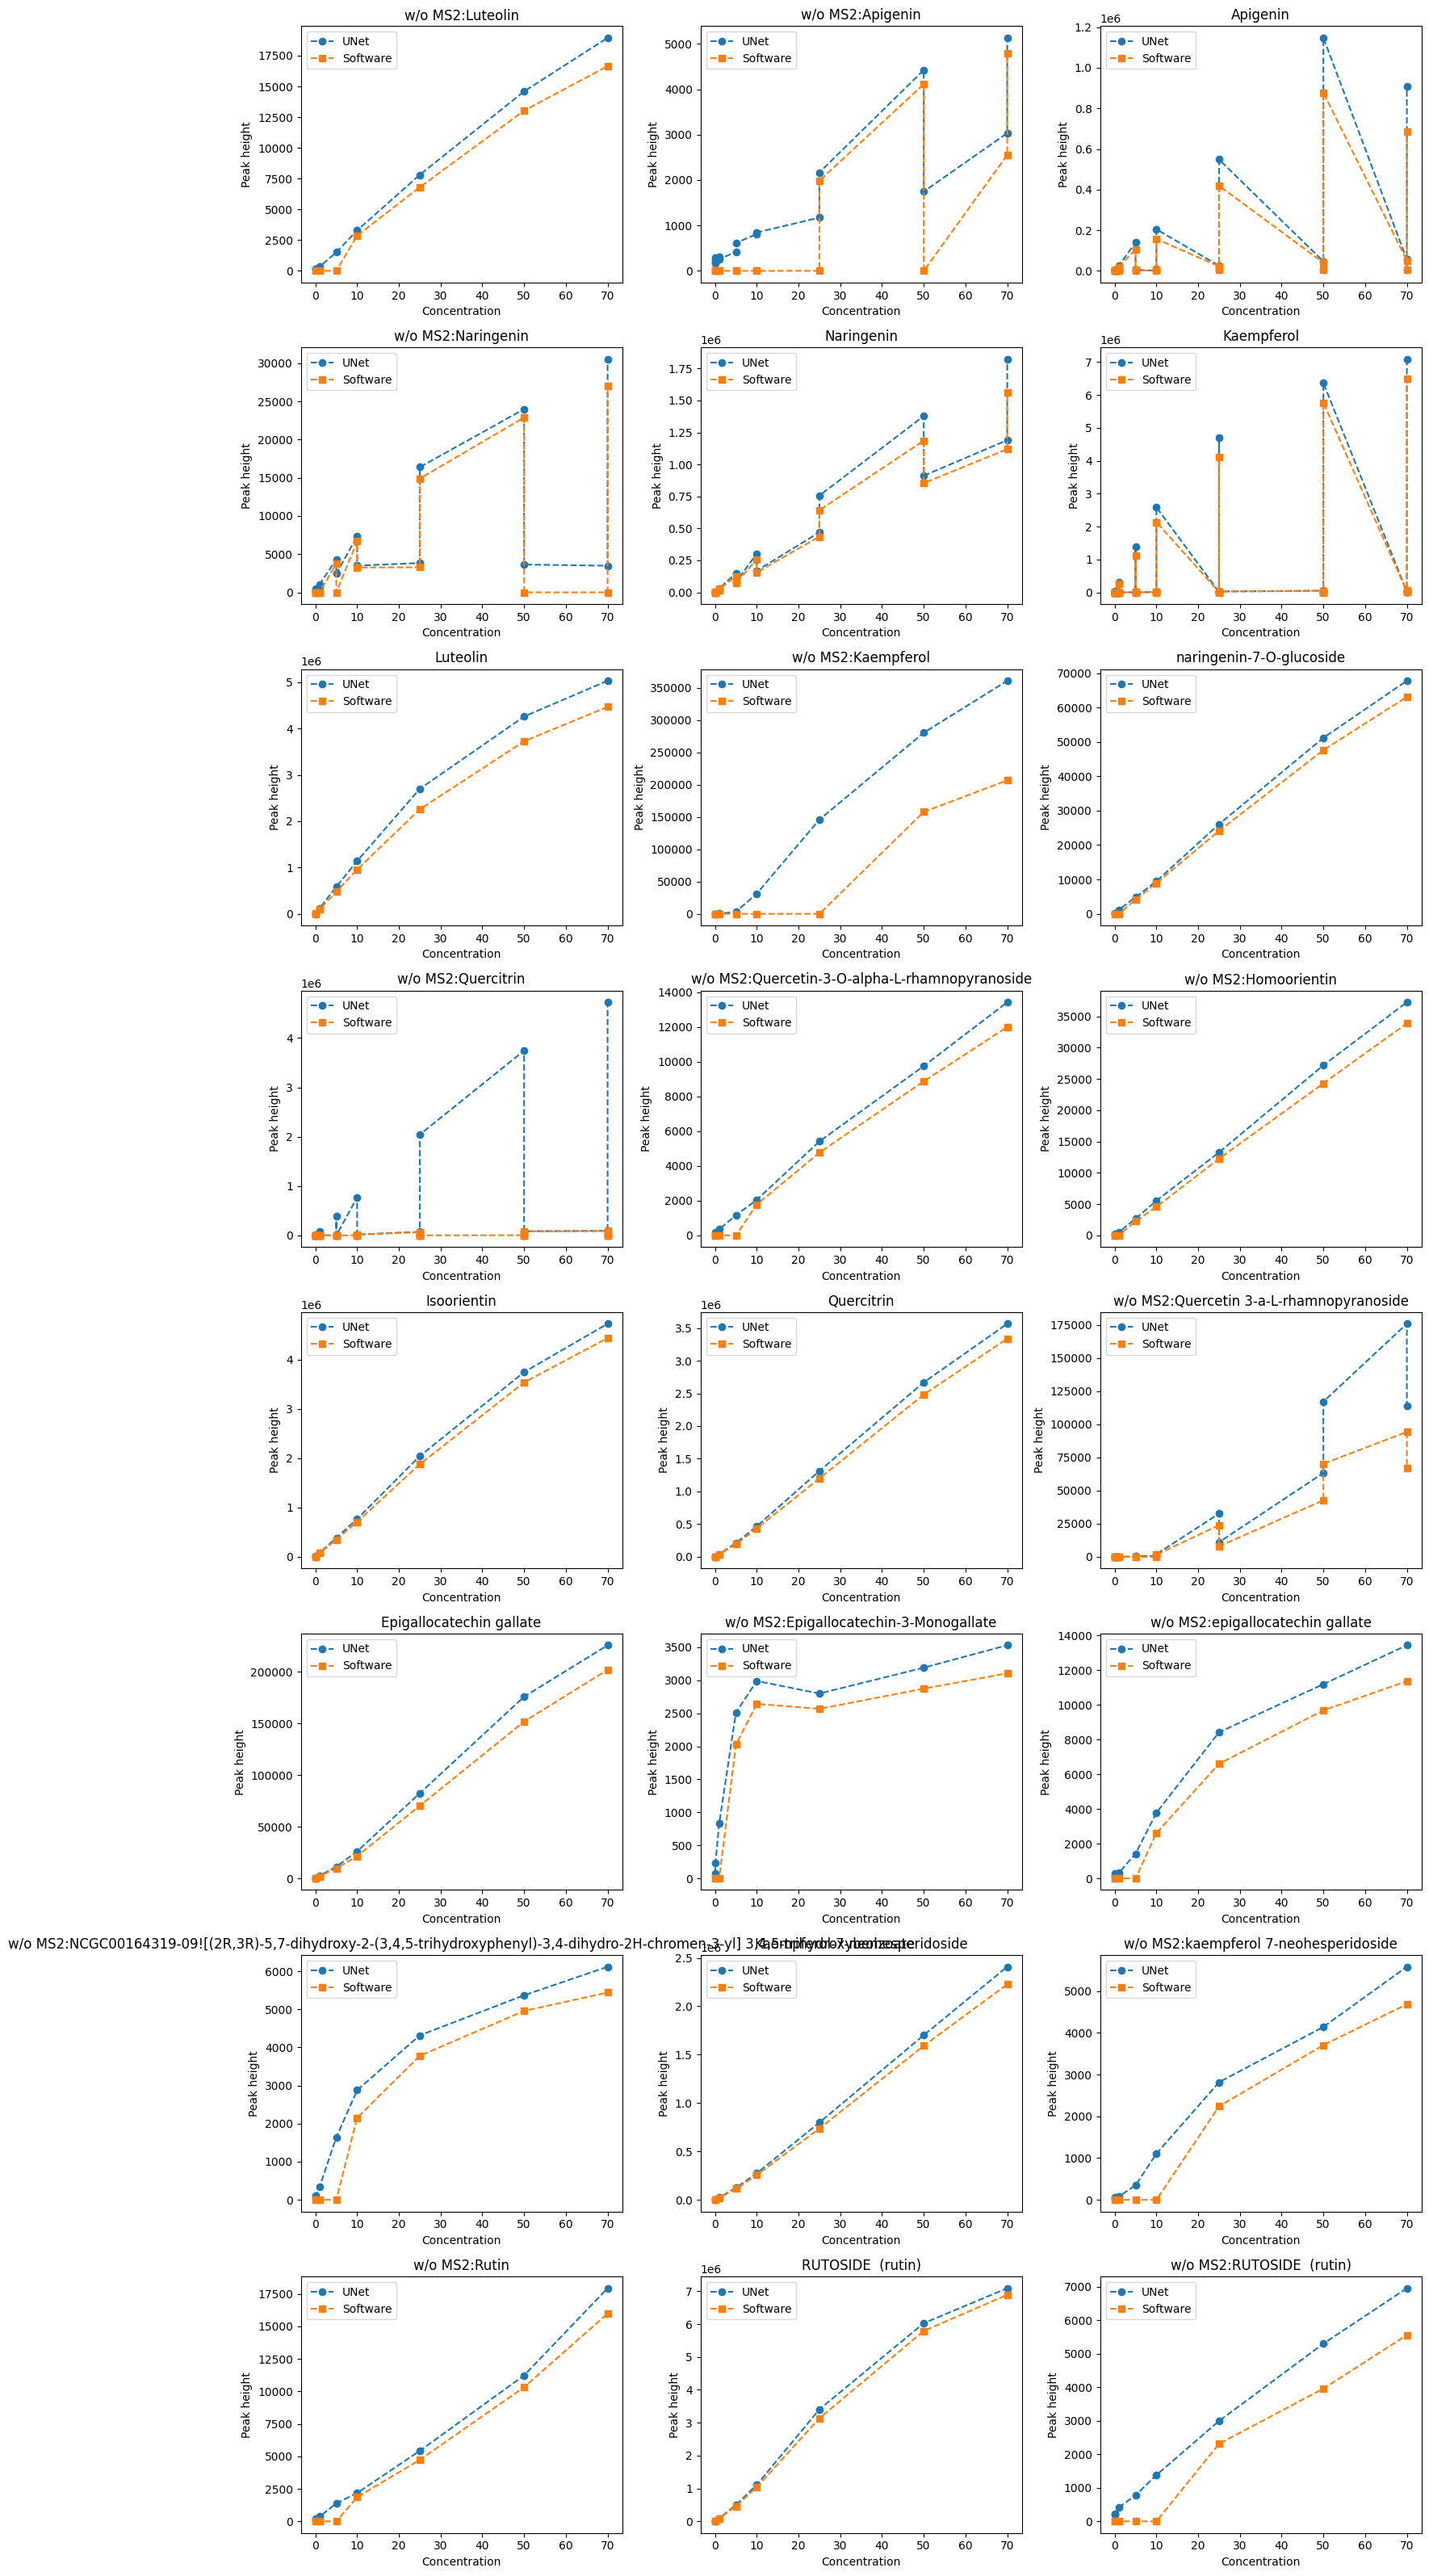

In [ ]:
# Calibration curve per compounds - Matrix standards only

compounds = comparison_table["Compound"].unique()

ncols = 3
nrows = math.ceil(len(compounds) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)

for i, compound in enumerate(compounds):
    row = i // ncols
    col = i % ncols
    ax = axes[row][col]

    sub = comparison_table[comparison_table["Compound"] == compound].copy()
    sub = sub.sort_values("Concentration")

    ax.plot(sub["Concentration"], sub["UNet height"], linestyle="--", marker="o", label="UNet")
    ax.plot(sub["Concentration"], sub["Software height"], linestyle="--", marker="s", label="Software")

    ax.set_title(compound)
    ax.set_xlabel("Concentration")
    ax.set_ylabel("Peak height")
    ax.legend()

for j in range(len(compounds), nrows * ncols):
    row = j // ncols
    col = j % ncols
    axes[row][col].axis("off")

plt.tight_layout()
plt.show()

/tmp/ipykernel_2567650/3918709681.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["compound_id"] = df["Compound"].astype(str) + " | " + df["MS1 label"].astype(str)
/tmp/ipykernel_2567650/3918709681.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["compound_short"] = df["Compound"].astype(str).str.slice(0, 20) + "... | " + df["MS1 label"].astype(str).str.replace(task_name, "", regex=True).str.slice(0, 22)
/tmp/ipykernel_2567650/3918709681.py:16: SettingWithCopyWarning: 
A value is trying to be s

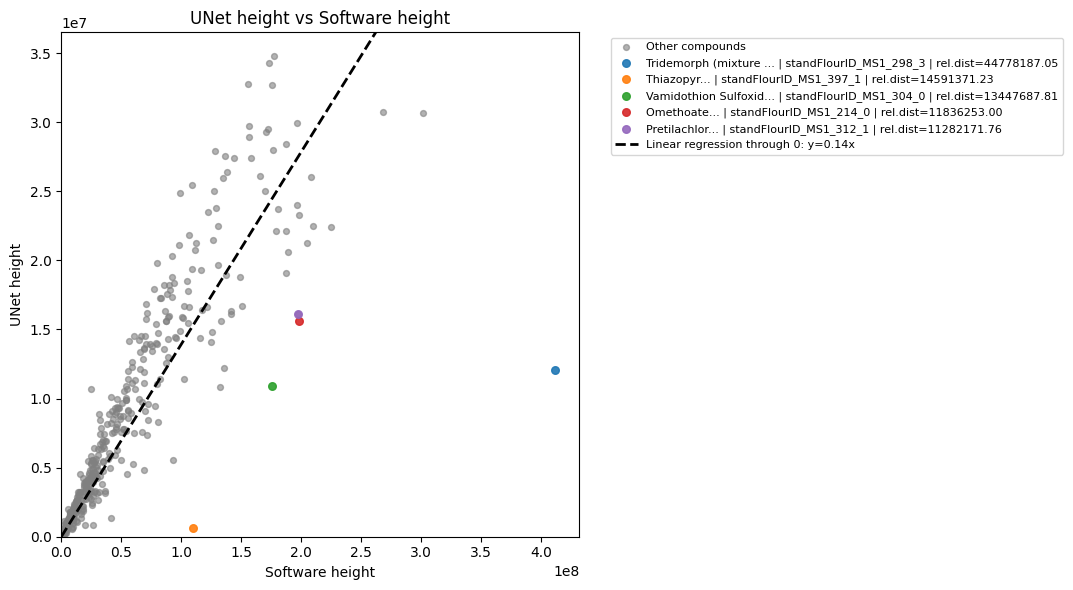

In [14]:
# Calibration curve - all compounds
df = comparison_table

df["UNet height"] = pd.to_numeric(df["UNet height"], errors="coerce")
df["Software height"] = pd.to_numeric(df["Software height"], errors="coerce")
df = df.dropna(subset=["UNet height", "Software height"])

df["compound_id"] = df["Compound"].astype(str) + " | " + df["MS1 label"].astype(str)
df["compound_short"] = df["Compound"].astype(str).str.slice(0, 20) + "... | " + df["MS1 label"].astype(str).str.replace(task_name, "", regex=True).str.slice(0, 22)

x = df["Software height"].values
y = df["UNet height"].values

slope = np.sum(x * y) / np.sum(x * x)

df["distance"] = np.abs(slope * df["Software height"] - df["UNet height"]) / np.sqrt(slope**2 + 1)

dist_table = df.groupby("compound_id").agg(mean_distance=("distance", "mean"), compound_short=("compound_short", "first")).reset_index()

N = 5
worstN = dist_table.sort_values("mean_distance", ascending=False).head(N)
worst_ids = set(worstN["compound_id"])
normal = df[~df["compound_id"].isin(worst_ids)]

x_line = np.linspace(0, x.max() * 1.05, 200)
y_line = slope * x_line

plt.figure(figsize=(11, 6))

plt.scatter(normal["Software height"], normal["UNet height"], s=18, alpha=0.6, color="grey", label="Other compounds")

for _, row in worstN.iterrows():
    sub = df[df["compound_id"] == row["compound_id"]]
    plt.scatter(sub["Software height"], sub["UNet height"], s=30, alpha=0.9, label=f"{row['compound_short']} | rel.dist={row['mean_distance']:.2f}")

plt.plot(x_line, y_line, linestyle="--", linewidth=2, color="black", label=f"Linear regression through 0: y={slope:.2f}x")

plt.xlabel("Software height")
plt.ylabel("UNet height")
plt.title("UNet height vs Software height")

plt.xlim(0, x.max() * 1.05)
plt.ylim(0, y.max() * 1.05)

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

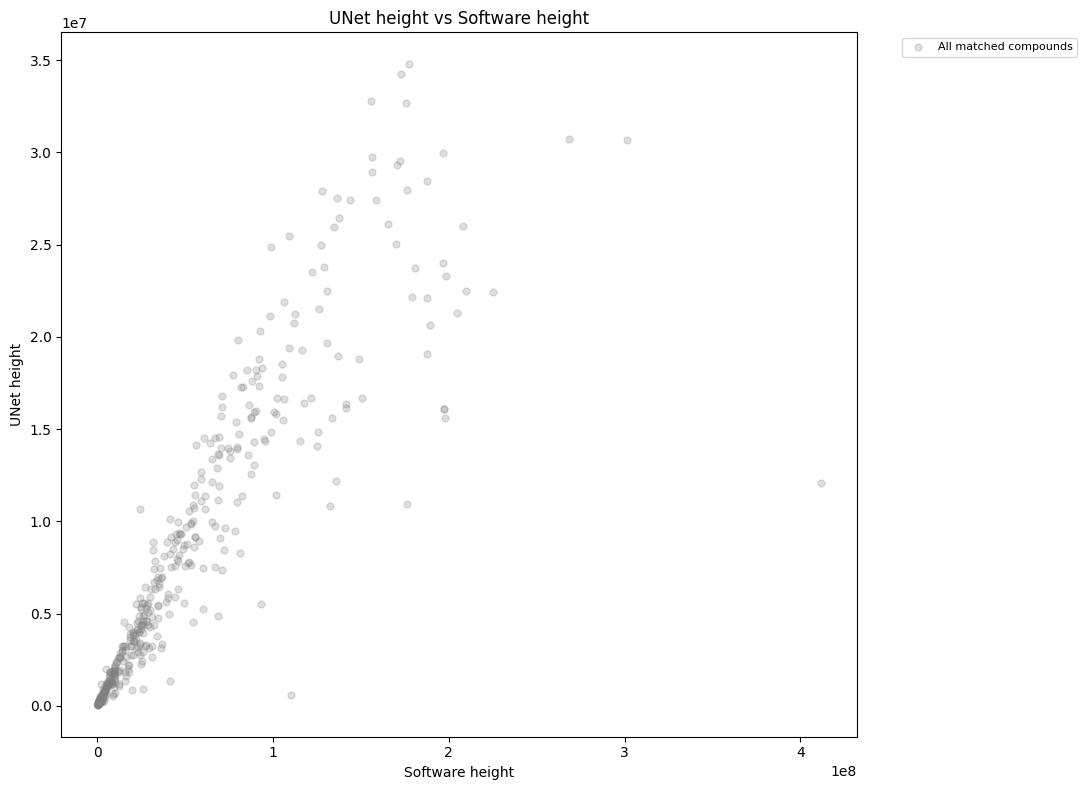

In [16]:
plt.figure(figsize=(11, 8))

# All non-highlighted points
plt.scatter(
    df["Software height"],
    df["UNet height"],
    s=25,
    alpha=0.25,
    color="grey",
    label="All matched compounds"
)
plt.xlabel("Software height")
plt.ylabel("UNet height")
plt.title("UNet height vs Software height")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left",fontsize=8)
plt.tight_layout()
plt.show()

In [4]:
not_matched

NameError: name 'not_matched' is not defined

Just checking for any false negatives from the software

In [7]:
# Flourine ID
# Creating a table for comparison between UNet and another method (and/or expected concentrations)
compound_info = pd.DataFrame()
not_matched = pd.DataFrame()

n_comp = len(compound_undetected)
print(f"Working with {n_comp} compounds")
n_matched = 0
#n_comp = 5

for i in range(n_comp):

    expected_mz = compound_undetected['mz'].iloc[i]
    expected_rt = compound_undetected['RT'].iloc[i]
    adduct = compound_undetected['adduct'].iloc[i]
   
    print(f'Compound #{i}: {compound_undetected['Compound'].iloc[i]} - m/z = {expected_mz}, RT = {expected_rt}')

    # Finding single labels with the same mass range
    all_labels = [
        f for f in os.listdir(single_labels_path)
        if (float(f.split('_')[2] + '.' + f.split('_')[3]) <= expected_mz) &
        (float(f.split('_')[4] + '.' + re.sub('.npy', '', f.split('_')[5])) >= expected_mz) &
        (f.split('_')[1] == 'MS1')
    ]

    #print(all_labels)

    matched = False
    
    # Now going through all selected labels to find one that matches in RT 

    for j in range(len(all_labels)):    
        img =  np.load(os.path.join(single_labels_path, all_labels[j]))
        # Single label has 0s everywhere expect in the peak region
        if (img>0).any():
            rt_ind= np.unique(np.where(img>0)[1])
            # Turning it back into real-life RT terms to compare with the compound expected RT
            rt_range = [rt_bins[np.min(rt_ind)], rt_bins[np.max(rt_ind)]]
            # Checking if expected RT is inside of the single label
            if (expected_rt>=rt_range[0]) & (expected_rt<=rt_range[1]):
                # getting max peak heights in the label
                single_label = all_labels[j]
                mz_range = [float(single_label.split('_')[2]+'.'+single_label.split('_')[3]), float(single_label.split('_')[4]+'.'+single_label.split('_')[5])]
                n_matched = n_matched + 1
                # getting precursor info
                # only FlourineId
                mass_slice = df_ms1[(df_ms1['mz']>=mz_range[0]) & (df_ms1['mz']<=mz_range[1]) & (df_ms1['RT']>=rt_range[0]) & (df_ms1['RT']<=rt_range[1]) & (df_ms1['mix']==compound_undetected['mix_cur'].iloc[i])].reset_index(drop = True)
                #mass_slice = df_ms1[(df_ms1['mz']>=mz_range[0]) & (df_ms1['mz']<=mz_range[1]) & (df_ms1['RT']>=rt_range[0]) & (df_ms1['RT']<=rt_range[1])].reset_index(drop = True)
                # general info on the compound
                if len(mass_slice) > 0:
                    matched = True
                    compound_info = pd.concat([compound_info, pd.DataFrame({'Compound': [compound_undetected['Compound'].iloc[i]],
                                                                            'MS1 label': [single_label],
                                                                            'precursor mass': [mass_slice.loc[np.argmax(mass_slice['inty']), 'mz']],
                                                                            'precursor int': [np.max(mass_slice['inty'])],
                                                                            'expected mass': expected_mz,
                                                                            'mz min': [mz_range[0]], 
                                                                            'mz max': [mz_range[1]],
                                                                            'expected RT': expected_rt, 
                                                                            'RT min': [rt_range[0]],
                                                                            'RT max': [rt_range[1]],
                                                                            #'inchikey':  [chrom_method_results['inchikey'].iloc[i]],
                                                                            #'MsDial MS2': [chrom_method_results['MS2'].iloc[i]],
                                                                            #'formula': [compound_undetected['formula'].iloc[i]],
                                                                            'adduct': adduct})], ignore_index=True)
        
    if not matched: not_matched = pd.concat([not_matched, compound_undetected.iloc[[i]]], ignore_index=True)

#print(f'No. of compounds not matched: {len(not_matched)}/{n_comp}')
print(f'No. of compounds matched: {round(len(compound_info)/n_comp, 2)*100}% ({len(compound_info)}/{n_comp})')
print(f'No. of compounds matched: {round(n_matched/n_comp, 2)*100}%')


Working with 247 compounds
Compound #0: Chlormequat Chloride - m/z = 123.0809521, RT = 62.400000000000006
Compound #1: Mepiquat Chloride - m/z = 115.135574515, RT = 63.6
Compound #2: Cyromazine - m/z = 167.10399433999999, RT = 68.39999999999999
Compound #3: Formetanate HCl - m/z = 222.12372673, RT = 69.0
Compound #4: Butoxycarboxim - m/z = 223.07472811, RT = 169.2
Compound #5: Aldicarb Sulfone - m/z = 223.07472811, RT = 187.20000000000002
Compound #6: Flonicamid - m/z = 230.05359631, RT = 284.40000000000003
Compound #7: Cymoxanil - m/z = 199.08259019, RT = 450.0
Compound #8: Butocarboxim - m/z = 191.08489887, RT = 469.20000000000005
Compound #9: Aldicarb - m/z = 191.08489887, RT = 500.4
Compound #10: Simetryn - m/z = 214.11211666999998, RT = 514.8
Compound #11: Prometon - m/z = 226.16626025, RT = 531.0
Compound #12: Terbumeton - m/z = 226.16626025, RT = 552.0
Compound #13: Methyl Paraoxon - m/z = 248.03187404, RT = 566.4
Compound #14: Carbaryl - m/z = 202.086278594, RT = 679.8
Compound

In [9]:
compound_info

,Compound,MS1 label,precursor mass,precursor int,expected mass,mz min,mz max,expected RT,RT min,RT max,adduct
0,Chlormequat Chloride,standFlourID_MS1_123_0_123_1_003.npy,123.043892,4.554552e+04,123.080952,123.0,123.1,62.4,61.20,253.64,[M+H]+
1,Formetanate HCl,standFlourID_MS1_222_1_222_2_003.npy,222.123337,4.642120e+05,222.123727,222.1,222.2,69.0,63.92,438.60,[M+H]+
2,Butoxycarboxim,standFlourID_MS1_223_0_223_1_001.npy,223.063324,2.651532e+05,223.074728,223.0,223.1,169.2,0.00,211.48,[M+H]+
3,Aldicarb Sulfone,standFlourID_MS1_223_0_223_1_001.npy,223.063324,2.651532e+05,223.074728,223.0,223.1,187.2,0.00,211.48,[M+H]+
4,Isoprocarb,standFlourID_MS1_194_1_194_2_003.npy,194.117233,2.211643e+06,194.117579,194.1,194.2,736.2,91.12,1164.84,[M+H]+
5,Sebuthylazin,standFlourID_MS1_230_1_230_2_007.npy,230.116333,8.190659e+04,230.116723,230.1,230.2,782.4,716.72,868.36,[M+H]+
6,Propazine,standFlourID_MS1_230_1_230_2_007.npy,230.116333,8.190659e+04,230.116723,230.1,230.2,793.2,716.72,868.36,[M+H]+
7,Terbuthylazine,standFlourID_MS1_230_1_230_2_007.npy,230.116333,8.190659e+04,230.116723,230.1,230.2,829.8,716.72,868.36,[M+H]+
8,Fenobucarb,standFlourID_MS1_208_1_208_2_013.npy,208.132996,1.074124e+05,208.133229,208.1,208.2,832.2,718.08,931.60,[M+H]+
9,Fenobucarb,standFlourID_MS1_208_1_208_2_024.npy,208.132874,1.026800e+05,208.133229,208.1,208.2,832.2,716.04,878.56,[M+H]+


Next step is to collect MS2 spectra for each MS1 label (aka compound label). MS2 spectra is constructed by selecting all MS2 labels in the correspoding MS1 cluster and extracting m/z and RT range of that MS2 label. Then raw spectra is extracting from the QC .mzml file and the top peak is selected together with it's m/z value as the reference (m/z, int) pair for that MS2 label. 

In [10]:
# Adding columns to save spectra in
compound_info['ms2_mz'] = None
compound_info['ms2_int'] = None

# Going through all clusters (corresponding to selected compounds) and extracting raw MS2 (max value within the mass slice and single label's RT range)
for i in range(len(compound_info)):
    # all ms2 in the clusters
    ms2_img = sorted(clusters.loc[clusters['ms1_name'] == compound_info['MS1 label'].iloc[i], 'ms2_name'].to_numpy())
    # collecting mz and int
    ms2_mz = []
    ms2_int = []
    
    for k in range(len(ms2_img)):
        # Getting m/z range
        mz_range = [float(ms2_img[k].split('_')[2]+'.'+ms2_img[k].split('_')[3]), float(ms2_img[k].split('_')[4]+'.'+ms2_img[k].split('_')[5])]
        # Getting RT range
        ms2_label =  np.load(os.path.join(single_labels_path, ms2_img[k]))
        rt_ind= np.unique(np.where(ms2_label>0)[1])
        rt_range = [rt_bins[np.min(rt_ind)],rt_bins[np.max(rt_ind)]]
        # Extracting highest peak point in that area
        mass_slice = df_ms2[(df_ms2['mz']>=mz_range[0]) & (df_ms2['mz']<=mz_range[1]) & (df_ms2['RT']>=rt_range[0]) & (df_ms2['RT']<=rt_range[1])].reset_index(drop = True)
        ms2_mz.append(mass_slice['mz'].iloc[np.argmax(mass_slice['inty'])])
        ms2_int.append(np.max(mass_slice['inty'])) 

    compound_info.at[i, "ms2_mz"] = np.round(np.array(ms2_mz, dtype=float), 3)
    compound_info.at[i, "ms2_int"] = np.array(ms2_int, dtype=float)

compound_info

,Compound,MS1 label,precursor mass,precursor int,expected mass,mz min,mz max,expected RT,RT min,RT max,formula,adduct,inchikey,MsDial MS2,ms2_mz,ms2_int
0,Apigenin,standNeg_MS1_269_0_269_1_005.npy,269.046204,908188.0,269.04593,269.0,269.1,1057.50,1054.11,1063.60,C15H10O5,[M-H]-,KZNIFHPLKGYRTM-UHFFFAOYSA-N,117.03476:6301 149.0238:1043 151.00272:887 159...,"[225.056, 269.046, 270.048, 358.941]","[4695.09375, 36904.53125, 5372.625, 8653.171875]"
1,Naringenin,standNeg_MS1_271_0_271_1_003.npy,271.061798,1189919.0,271.06168,271.0,271.1,708.54,702.25,716.85,C15H12O5,[M-H]-,FTVWIRXFELQLPI-ZDUSSCGKSA-N,65.00267:2184 83.01344:2046 93.03375:2071 99.9...,"[119.05, 165.019, 218.976, 273.977, 309.001, 3...","[69005.8125, 3604.595703125, 9225.578125, 7145..."
2,Naringenin,standNeg_MS1_271_0_271_1_006.npy,271.061798,1821905.0,271.06180,271.0,271.1,1017.84,1013.23,1023.45,C15H12O5,[M-H]-,FTVWIRXFELQLPI-ZDUSSCGKSA-N,65.00342:2532 83.01388:1460 93.03435:2690 99.9...,"[107.013, 1140.177, 1141.18, 1142.181, 1143.18...","[12133.1875, 65097.03125, 43725.8125, 15211.33..."
3,Luteolin,standNeg_MS1_285_0_285_1_005.npy,285.042389,5031856.0,285.04239,285.0,285.1,1027.32,1022.72,1033.67,C15H10O6,[M-H]-,IQPNAANSBPBGFQ-UHFFFAOYSA-N,65.00364:3612 77.04002:1007 83.01476:2346 89.0...,"[104.026, 105.034, 107.013, 115.019, 121.029, ...","[6808.3515625, 8254.0390625, 19169.3125, 5626...."
4,Kaempferol,standNeg_MS1_285_0_285_1_006.npy,285.044250,7086228.0,285.04425,285.0,285.1,1051.92,1047.54,1057.76,C15H10O6,[M-H]-,IYRMWMYZSQPJKC-UHFFFAOYSA-N,93.03431:3253 107.01265:2240 108.02118:2386 10...,"[108.021, 109.029, 128.027, 129.034, 130.042, ...","[10637.75, 7613.31640625, 3364.283203125, 1298..."
5,Isoorientin,standNeg_MS1_447_0_447_1_002.npy,447.093933,4723148.0,447.09393,447.0,447.1,563.34,556.98,570.85,C21H20O11,[M-H]-,ODBRNZZJSYPIDI-VJXVFPJBSA-N,133.02879:3574 221.13382:1303 227.10767:708 26...,"[108.021, 109.029, 1177.321, 117.034, 119.013,...","[4972.38671875, 10088.03125, 2689.404296875, 5..."
6,Quercitrin,standNeg_MS1_447_0_447_1_005.npy,447.093872,3564304.0,447.09436,447.0,447.1,846.12,838.76,854.82,C21H20O11,[M-H]-,OXGUCUVFOIWWQJ-HQBVPOQASA-N,65.00391:1231 83.01372:1289 107.01331:6123 108...,"[107.014, 108.021, 109.03, 119.013, 120.021, 1...","[18390.140625, 8559.375, 9030.625, 3987.638671..."
7,Epigallocatechin gallate,standNeg_MS1_457_0_457_1_001.npy,457.077423,224886.0,457.07648,457.0,457.1,342.54,337.25,347.47,C22H18O11,[M-H]-,WMBWREPUVVBILR-WIYYLYMNSA-N,95.01359:1306 109.02995:2097 117.03436:961 121...,"[164.012, 169.015, 193.015, 305.066, 391.945, ...","[3850.78515625, 26588.0, 33103.28125, 6670.726..."
8,Kaempferol-7-neohesperidoside,standNeg_MS1_593_1_593_2_001.npy,593.152100,2408438.0,593.15210,593.1,593.2,826.62,820.51,833.65,C27H30O15,[M-H]-,ZEJXENDZTYVXDP-CSJHBIPPSA-N,151.00349:2829 255.02771:1622 257.0459:1598 28...,"[107.013, 151.004, 152.007, 164.011, 185.06, 2...","[11581.375, 47812.46875, 4337.74609375, 5726.4..."
9,RUTOSIDE (rutin),standNeg_MS1_609_1_609_2_001.npy,609.148071,7091548.0,609.14807,609.1,609.2,720.90,713.93,729.26,C27H30O16,[M-H]-,IKGXIBQEEMLURG-NVPNHPEKSA-N,107.0136:1441 151.0042:9039 163.00304:1691 178...,"[107.013, 108.02, 109.029, 121.029, 135.009, 1...","[22647.15625, 5063.86328125, 3938.794921875, 8..."


In [11]:
compound_info.to_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/info_L3.xlsx", index=False)

Next, lets run Sirius on the collected MS2 spectra as detected by UNet (and postprocessed and clustered). First, Sirius requires login.

In [16]:
# Function to run Sirius - writing .ms files and running formula annotation through CLI

def sirius_login_prompt(sirius_path, username):
    password = getpass.getpass("SIRIUS password: ")

    cmd = [
        sirius_path,
        "login",
        "-u", username,
        "-p",
    ]

    result = subprocess.run(
        cmd,
        input=password + "\n",
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace",
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"SIRIUS login failed with return code {result.returncode}\n\n"
            f"STDERR:\n{result.stderr}\n\n"
            f"STDOUT:\n{result.stdout}"
        )

    return result

def _safe_project_name(text):
    text = str(text).strip()
    text = re.sub(r"[^A-Za-z0-9_-]+", "_", text)
    text = re.sub(r"_+", "_", text)
    text = text.strip("_")
    return text


def write_sirius_ms_file(compound_name, parent_mass, precursor_int, ion_type, ms2_mz, ms2_int, output_dir, min_ms2_int=None):
    """
    Create one SIRIUS .ms file from explicit inputs.
    """
    compound_name = str(compound_name)
    parent_mass = float(parent_mass)
    precursor_int = float(precursor_int)
    ion_type = str(ion_type)

    ms2_mz = np.asarray(ms2_mz, dtype=float)
    ms2_int = np.asarray(ms2_int, dtype=float)

    if len(ms2_mz) == 0:
        raise ValueError(f"No MS2 peaks found for {compound_name}")

    if len(ms2_mz) != len(ms2_int):
        raise ValueError(
            f"ms2_mz and ms2_int must have same length for {compound_name}"
        )

    # Remove fragments above precursor mass
    keep = ms2_mz < parent_mass
    ms2_mz = ms2_mz[keep]
    ms2_int = ms2_int[keep]

    if len(ms2_mz) == 0:
        raise ValueError(f"No MS2 peaks below precursor mass for {compound_name}")

    # Sort by m/z
    order = np.argsort(ms2_mz)
    ms2_mz = ms2_mz[order]
    ms2_int = ms2_int[order]

    # Optional filtering
    if min_ms2_int is not None:
        keep = ms2_int >= float(min_ms2_int)
        ms2_mz = ms2_mz[keep]
        ms2_int = ms2_int[keep]

    if len(ms2_mz) == 0:
        raise ValueError(f"All MS2 peaks removed after filtering for {compound_name}")

    os.makedirs(output_dir, exist_ok=True)
    ms_file_path = os.path.join(output_dir, f"{_safe_project_name(compound_name)}.ms")

    with open(ms_file_path, "w", encoding="utf-8") as f:
        f.write(f">compound {compound_name}\n")
        f.write(f">parentmass {parent_mass:.6f}\n")
        f.write(f">ionization {ion_type}\n")
        f.write("\n")

        f.write(">ms1\n")
        f.write(f"{parent_mass:.6f} {precursor_int:.6f}\n")
        f.write("\n")

        f.write(">ms2\n")
        for mz, intensity in zip(ms2_mz, ms2_int):
            f.write(f"{mz:.6f} {intensity:.6f}\n")

    return ms_file_path

def get_sirius_formula_matches(sirius_path, ms_file_path, project_path, output_dir, profile="qtof", top_k=20, run_fingerprints=False):
    
    # Making project directory
    project_dir = os.path.dirname(project_path)
    os.makedirs(project_dir, exist_ok=True)

    # Clearing previous outputs
    if os.path.exists(project_path):
        os.remove(project_path)
    if os.path.exists(output_dir):
        shutil.rmtree(output_dir)
    os.makedirs(output_dir, exist_ok=True)

    # Running formulas
    cmd = [
        sirius_path,
        "--input", ms_file_path,
        "--project", project_path,
        "formulas",
        "-p", profile,
    ]

    if run_fingerprints:
        cmd.append("fingerprints")

    # Extracting summaries
    cmd.extend([
        "summaries",
        "--format=TSV",
        f"--top-k-summary={top_k}",
        "-o", output_dir,
    ])

    result = subprocess.run(
        cmd,
        capture_output=True,
        text=True,
        encoding="utf-8",
        errors="replace"
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"SIRIUS failed with return code {result.returncode}\n\n"
            f"STDERR:\n{result.stderr}\n\n"
            f"STDOUT:\n{result.stdout}"
        )

    formula_file = os.path.join(output_dir, f"formula_identifications_top-{top_k}.tsv")
    if not os.path.exists(formula_file):
        raise FileNotFoundError(
            f"formula_identifications.tsv not found in {output_dir}\n\n"
            f"STDERR:\n{result.stderr}\n\n"
            f"STDOUT:\n{result.stdout}"
        )

    return pd.read_csv(formula_file, sep="\t")

In [ ]:
# Login into Sirius
login_result = sirius_login_prompt(
    sirius_path=r"REDACTED",
    username="REDACTED",
)

#print(login_result.stdout)

In [13]:
# Running all standards through Sirius
compound_info['Sirius score (UNet)'] = None

for comp_ind in range(len(compound_info)):

    # Getting MsDial reported formula
    expected_formula = compound_info["formula"].iloc[comp_ind]
   
    # Making sure that the compound name is compatible with Sirius
    compound_name = _safe_project_name(compound_info["Compound"].iloc[comp_ind])
    
    # Output folder
    base_out = f"C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/{compound_name}"

    # Creating Sirius project and summaries folder
    project_path = os.path.join(base_out, f"{compound_name}_project.sirius")
    output_dir = os.path.join(base_out, f"{compound_name}_summary")

    # Creating .ms file
    ms_file = write_sirius_ms_file(
        compound_name=compound_info["Compound"].iloc[comp_ind],
        parent_mass=compound_info["precursor mass"].iloc[comp_ind],
        precursor_int=compound_info["precursor int"].iloc[comp_ind],
        ion_type=compound_info["adduct"].iloc[comp_ind],
        ms2_mz=compound_info["ms2_mz"].iloc[comp_ind],
        ms2_int=compound_info["ms2_int"].iloc[comp_ind],
        output_dir=base_out,
        min_ms2_int=5000
    )

    print(ms_file)

    # Running Sirius through command line
    formula_matches = get_sirius_formula_matches(
        sirius_path=r"C:\Users\frz603\Desktop\sirius\sirius.exe",
        ms_file_path=ms_file,
        project_path=project_path,
        output_dir=output_dir,
        profile="qtof",
        top_k=20,
        run_fingerprints=False
    )

    # Getting top 20 matches and checking if the expected formula is among them
    matches = formula_matches[formula_matches["molecularFormula"] == expected_formula]

    # Adding Sirius score to the table (if the formula matches)
    if not matches.empty:
        compound_info.loc[comp_ind, "Sirius score (UNet)"] = matches.iloc[0]["SiriusScore"]

compound_info

C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/Apigenin\Apigenin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/Naringenin\Naringenin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/Luteolin\Luteolin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/Kaempferol\Kaempferol.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/Isoorientin\Isoorientin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/Kaempferol-7-neohesperidoside\Kaempferol-7-neohesperidoside.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/UNet/RUTOSIDE_rutin\RUTOSIDE_rutin.ms


,Compound,MS1 label,precursor mass,precursor int,mz min,mz max,RT min,RT max,formula,adduct,MsDial MS2,ms2_mz,ms2_int,Sirius score (UNet)
0,Apigenin,standNeg_MS1_269_0_269_1_004.npy,269.046204,908188.0,269.0,269.1,1055.57,1067.25,C15H10O5,[M-H]-,117.03476:6301 149.0238:1043 151.00272:887 159...,"[149.025, 159.893, 181.066, 196.052, 225.056, ...","[7208.4765625, 1095.2578125, 2167.912109375, 2...",4.388
1,Naringenin,standNeg_MS1_271_0_271_1_006.npy,271.061798,1821905.0,271.0,271.1,1011.04,1026.37,C15H12O5,[M-H]-,65.00342:2532 83.01388:1460 93.03435:2690 99.9...,"[1138.181, 1140.177, 1141.18, 1142.181, 1143.1...","[3365.873046875, 65097.03125, 43725.8125, 1521...",56.934
2,Luteolin,standNeg_MS1_285_0_285_1_004.npy,285.042389,5031856.0,285.0,285.1,1019.07,1034.40,C15H10O6,[M-H]-,65.00364:3612 77.04002:1007 83.01476:2346 89.0...,"[104.026, 105.034, 107.013, 108.019, 115.019, ...","[6808.3515625, 8254.0390625, 19169.3125, 1679....",98.214
3,Kaempferol,standNeg_MS1_285_0_285_1_005.npy,285.044250,7086228.0,285.0,285.1,1046.81,1061.41,C15H10O6,[M-H]-,93.03431:3253 107.01265:2240 108.02118:2386 10...,"[105.034, 107.014, 108.021, 109.029, 115.054, ...","[3233.580078125, 11712.046875, 10637.75, 7613....",None
4,Isoorientin,standNeg_MS1_447_0_447_1_001.npy,447.093933,4723148.0,447.0,447.1,554.79,574.50,C21H20O11,[M-H]-,133.02879:3574 221.13382:1303 227.10767:708 26...,"[1075.363, 1076.365, 107.014, 108.021, 109.029...","[24566.359375, 15276.7265625, 5917.8125, 4972....",145.709
5,Kaempferol-7-neohesperidoside,standNeg_MS1_593_1_593_2_000.npy,593.152100,2408438.0,593.1,593.2,817.59,838.03,C27H30O15,[M-H]-,151.00349:2829 255.02771:1622 257.0459:1598 28...,"[103.055, 107.013, 108.018, 111.008, 111.009, ...","[3806.876953125, 11581.375, 1340.658203125, 42...",42.439
6,RUTOSIDE (rutin),standNeg_MS1_609_1_609_2_000.npy,609.148071,7091548.0,609.1,609.2,711.74,731.45,C27H30O16,[M-H]-,107.0136:1441 151.0042:9039 163.00304:1691 178...,"[108.02, 109.029, 1126.152, 121.029, 125.024, ...","[5063.86328125, 3938.794921875, 2195.7421875, ...",52.782


Lets run Sirius now on MsDial MS2 as well in order to make a comparison. 

In [43]:
def parse_msdial_ms2(ms2_string):
   
    mzs = []
    ints = []

    for token in str(ms2_string).split():
        
        mz, inten = token.split(":", 1)
        
        mzs.append(float(mz))
        ints.append(float(inten))

    return np.asarray(mzs, dtype=float), np.asarray(ints, dtype=float)

In [16]:
# Running Sirius on MsDial results
compound_info['Sirius score (MsDial)'] = None

for comp_ind in range(len(compound_info)):
    
    # Getting MsDial reported formula
    expected_formula = compound_info["formula"].iloc[comp_ind]

    # Parsing MsDial MS 
    ms2_mz, ms2_int = parse_msdial_ms2(compound_info["MsDial MS2"].iloc[comp_ind])

    # Checking if compound name is compatible with Sirius
    compound_name = _safe_project_name(compound_info["Compound"].iloc[comp_ind])
    
    # Output folder
    base_out = f"C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/{compound_name}"

    #Creating Sirius project and summaries folder
    project_path = os.path.join(base_out, f"{compound_name}_project.sirius")
    output_dir = os.path.join(base_out, f"{compound_name}_summary")

    # Writing .ms file
    ms_file = write_sirius_ms_file(
        compound_name=compound_info["Compound"].iloc[comp_ind],
        parent_mass=compound_info["precursor mass"].iloc[comp_ind],
        precursor_int=compound_info["precursor int"].iloc[comp_ind],
        ion_type=compound_info["adduct"].iloc[comp_ind],
        ms2_mz=ms2_mz,
        ms2_int=ms2_int,
        output_dir=base_out,
        min_ms2_int=5000
    )

    print(ms_file)

    # Running Sirius through command line
    formula_matches = get_sirius_formula_matches(
        sirius_path=r"C:\Users\frz603\Desktop\sirius\sirius.exe",
        ms_file_path=ms_file,
        project_path=project_path,
        output_dir=output_dir,
        profile="qtof",
        top_k=20,
        run_fingerprints=False
    )

    # Chekcing if there are any matches in formula
    matches = formula_matches[formula_matches["molecularFormula"] == expected_formula]

    # Adding Sirius score
    if not matches.empty:
        compound_info.loc[comp_ind, "Sirius score (MsDial)"] = matches.iloc[0]["SiriusScore"]

compound_info

C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/Apigenin\Apigenin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/Naringenin\Naringenin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/Luteolin\Luteolin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/Kaempferol\Kaempferol.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/Isoorientin\Isoorientin.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/Kaempferol-7-neohesperidoside\Kaempferol-7-neohesperidoside.ms
C:/Users/frz603/Documents/DSP/Matrix_Standards/Sirius/MsDial/RUTOSIDE_rutin\RUTOSIDE_rutin.ms


,Compound,MS1 label,precursor mass,precursor int,mz min,mz max,RT min,RT max,formula,adduct,MsDial MS2,ms2_mz,ms2_int,Sirius score (UNet),Sirius score (MsDial)
0,Apigenin,standNeg_MS1_269_0_269_1_004.npy,269.046204,908188.0,269.0,269.1,1055.57,1067.25,C15H10O5,[M-H]-,117.03476:6301 149.0238:1043 151.00272:887 159...,"[149.025, 159.893, 181.066, 196.052, 225.056, ...","[7208.4765625, 1095.2578125, 2167.912109375, 2...",4.388,14.126
1,Naringenin,standNeg_MS1_271_0_271_1_006.npy,271.061798,1821905.0,271.0,271.1,1011.04,1026.37,C15H12O5,[M-H]-,65.00342:2532 83.01388:1460 93.03435:2690 99.9...,"[1138.181, 1140.177, 1141.18, 1142.181, 1143.1...","[3365.873046875, 65097.03125, 43725.8125, 1521...",56.934,58.908
2,Luteolin,standNeg_MS1_285_0_285_1_004.npy,285.042389,5031856.0,285.0,285.1,1019.07,1034.40,C15H10O6,[M-H]-,65.00364:3612 77.04002:1007 83.01476:2346 89.0...,"[104.026, 105.034, 107.013, 108.019, 115.019, ...","[6808.3515625, 8254.0390625, 19169.3125, 1679....",98.214,56.614
3,Kaempferol,standNeg_MS1_285_0_285_1_005.npy,285.044250,7086228.0,285.0,285.1,1046.81,1061.41,C15H10O6,[M-H]-,93.03431:3253 107.01265:2240 108.02118:2386 10...,"[105.034, 107.014, 108.021, 109.029, 115.054, ...","[3233.580078125, 11712.046875, 10637.75, 7613....",None,None
4,Isoorientin,standNeg_MS1_447_0_447_1_001.npy,447.093933,4723148.0,447.0,447.1,554.79,574.50,C21H20O11,[M-H]-,133.02879:3574 221.13382:1303 227.10767:708 26...,"[1075.363, 1076.365, 107.014, 108.021, 109.029...","[24566.359375, 15276.7265625, 5917.8125, 4972....",145.709,30.059
5,Kaempferol-7-neohesperidoside,standNeg_MS1_593_1_593_2_000.npy,593.152100,2408438.0,593.1,593.2,817.59,838.03,C27H30O15,[M-H]-,151.00349:2829 255.02771:1622 257.0459:1598 28...,"[103.055, 107.013, 108.018, 111.008, 111.009, ...","[3806.876953125, 11581.375, 1340.658203125, 42...",42.439,13.593
6,RUTOSIDE (rutin),standNeg_MS1_609_1_609_2_000.npy,609.148071,7091548.0,609.1,609.2,711.74,731.45,C27H30O16,[M-H]-,107.0136:1441 151.0042:9039 163.00304:1691 178...,"[108.02, 109.029, 1126.152, 121.029, 125.024, ...","[5063.86328125, 3938.794921875, 2195.7421875, ...",52.782,44.45


In [44]:
# Cosine similarity 

def get_match_factor(sp1, sp2, tol=0.1):

    # Sorting by mz first within the method
    sp1 = sp1.sort_values(by=["mz"]).reset_index(drop = True)
    sp2 = sp2.sort_values(by=["mz"]).reset_index(drop = True)

    # Define example spectra    
    spectrum1 = Spectrum(mz=sp1['mz'].to_numpy(), intensities=sp1['int'].to_numpy(), metadata={})
    spectrum2 = Spectrum(mz=sp2['mz'].to_numpy(), intensities=sp2['int'].to_numpy(), metadata={})

    # Use cosine similarity (similar to match factor)
    similarity_function = CosineGreedy(tolerance=tol)
    score = similarity_function.pair(spectrum1, spectrum2)

    similarity_score = score["score"]
    matches = score["matches"]

    #print("Similarity score:", similarity_score)
    #print("Number of matching peaks:", matches)

    return similarity_score, matches


Next it could be useful to compare UNet acquired MS2 spectrum to the ground truth (DDA fragments). Here I'm using 4 metrics:
1. Cosine similarity
2. Precision
3. Recall
4. F1

I'm running the same metrics on MsDial to compare, as well as making comparison between UNet and MsDial. 

In [45]:
# Spectral similarity between UNet and MsDial
compound_info['MF (UNet_MsDial)'] = np.nan

for comp_ind in range(len(compound_info)):

    # Parsing MsDial deconvoluted MS2 and putting it into a nicer format
    ms2_mz, ms2_int = parse_msdial_ms2(compound_info["MsDial MS2"].iloc[comp_ind])
    msdial_ms2 = pd.DataFrame({'mz': ms2_mz, 'int': ms2_int})
    #print(msdial_ms2)

    # U-Net MS2
    unet_ms2 = pd.DataFrame({'mz': compound_info['ms2_mz'].iloc[comp_ind], 'int': compound_info['ms2_int'].iloc[comp_ind]})
    unet_ms2 = unet_ms2[unet_ms2['mz']<=(np.max(msdial_ms2['mz'])+1)]
    #print(unet_ms2)

    # Calculating number of matches and cosine similarity (with tol 0.1)
    mf, no_matches = get_match_factor(unet_ms2, msdial_ms2, 0.5)
    compound_info.loc[comp_ind, 'MF (UNet_MsDial)'] = mf

compound_info

,Compound,MS1 label,precursor mass,precursor int,expected mass,mz min,mz max,expected RT,RT min,RT max,formula,adduct,MsDial MS2,ms2_mz,ms2_int,MF (UNet_MsDial)
0,Apigenin,standNeg_MS1_269_0_269_1_005.npy,269.046204,908188.0,269.04593,269.0,269.1,1057.50,1054.11,1063.60,C15H10O5,[M-H]-,117.03476:6301 149.0238:1043 151.00272:887 159...,"[225.056, 269.046, 270.048, 358.941]","[4695.09375, 36904.53125, 5372.625, 8653.171875]",0.656642
1,Naringenin,standNeg_MS1_271_0_271_1_003.npy,271.061798,1189919.0,271.06168,271.0,271.1,708.54,702.25,716.85,C15H12O5,[M-H]-,65.00267:2184 83.01344:2046 93.03375:2071 99.9...,"[119.05, 165.019, 218.976, 273.977, 309.001, 3...","[69005.8125, 3604.595703125, 9225.578125, 7145...",0.856259
2,Naringenin,standNeg_MS1_271_0_271_1_006.npy,271.061798,1821905.0,271.06180,271.0,271.1,1017.84,1013.23,1023.45,C15H12O5,[M-H]-,65.00342:2532 83.01388:1460 93.03435:2690 99.9...,"[107.013, 1140.177, 1141.18, 1142.181, 1143.18...","[12133.1875, 65097.03125, 43725.8125, 15211.33...",0.954271
3,Luteolin,standNeg_MS1_285_0_285_1_005.npy,285.042389,5031856.0,285.04239,285.0,285.1,1027.32,1022.72,1033.67,C15H10O6,[M-H]-,65.00364:3612 77.04002:1007 83.01476:2346 89.0...,"[104.026, 105.034, 107.013, 115.019, 121.029, ...","[6808.3515625, 8254.0390625, 19169.3125, 5626....",0.994644
4,Kaempferol,standNeg_MS1_285_0_285_1_006.npy,285.044250,7086228.0,285.04425,285.0,285.1,1051.92,1047.54,1057.76,C15H10O6,[M-H]-,93.03431:3253 107.01265:2240 108.02118:2386 10...,"[108.021, 109.029, 128.027, 129.034, 130.042, ...","[10637.75, 7613.31640625, 3364.283203125, 1298...",0.923462
5,Isoorientin,standNeg_MS1_447_0_447_1_002.npy,447.093933,4723148.0,447.09393,447.0,447.1,563.34,556.98,570.85,C21H20O11,[M-H]-,133.02879:3574 221.13382:1303 227.10767:708 26...,"[108.021, 109.029, 1177.321, 117.034, 119.013,...","[4972.38671875, 10088.03125, 2689.404296875, 5...",0.984814
6,Quercitrin,standNeg_MS1_447_0_447_1_005.npy,447.093872,3564304.0,447.09436,447.0,447.1,846.12,838.76,854.82,C21H20O11,[M-H]-,65.00391:1231 83.01372:1289 107.01331:6123 108...,"[107.014, 108.021, 109.03, 119.013, 120.021, 1...","[18390.140625, 8559.375, 9030.625, 3987.638671...",0.951697
7,Epigallocatechin gallate,standNeg_MS1_457_0_457_1_001.npy,457.077423,224886.0,457.07648,457.0,457.1,342.54,337.25,347.47,C22H18O11,[M-H]-,95.01359:1306 109.02995:2097 117.03436:961 121...,"[164.012, 169.015, 193.015, 305.066, 391.945, ...","[3850.78515625, 26588.0, 33103.28125, 6670.726...",0.524502
8,Kaempferol-7-neohesperidoside,standNeg_MS1_593_1_593_2_001.npy,593.152100,2408438.0,593.15210,593.1,593.2,826.62,820.51,833.65,C27H30O15,[M-H]-,151.00349:2829 255.02771:1622 257.0459:1598 28...,"[107.013, 151.004, 152.007, 164.011, 185.06, 2...","[11581.375, 47812.46875, 4337.74609375, 5726.4...",0.998953
9,RUTOSIDE (rutin),standNeg_MS1_609_1_609_2_001.npy,609.148071,7091548.0,609.14807,609.1,609.2,720.90,713.93,729.26,C27H30O16,[M-H]-,107.0136:1441 151.0042:9039 163.00304:1691 178...,"[107.013, 108.02, 109.029, 121.029, 135.009, 1...","[22647.15625, 5063.86328125, 3938.794921875, 8...",0.730043


In [46]:
# Matching with DDA fragments and calculating precision, recall, f1 and cosine similarity for both msdial and unet
compound_info['MF (UNet_DDA)'] = np.nan
compound_info['MF (MsDial_DDA)'] = np.nan
compound_info['UNet precision'] = np.nan
compound_info['MsDial precision'] = np.nan
compound_info['UNet recall'] = np.nan
compound_info['MsDial recall'] = np.nan
compound_info['UNet F1'] = np.nan
compound_info['MsDial F1'] = np.nan

for comp_ind in range(len(compound_info)):

    # Parsing MsDial deconvoluted MS2 and putting it into a nicer format
    ms2_mz, ms2_int = parse_msdial_ms2(compound_info["MsDial MS2"].iloc[comp_ind])
    msdial_ms2 = pd.DataFrame({'mz': ms2_mz, 'int': ms2_int})
    #print(msdial_ms2)

    # U-Net MS2
    unet_ms2 = pd.DataFrame({'mz': compound_info['ms2_mz'].iloc[comp_ind], 'int': compound_info['ms2_int'].iloc[comp_ind]})
    unet_ms2 = unet_ms2[unet_ms2['mz']<=(np.max(msdial_ms2['mz'])+1)]
    #print(unet_ms2)

    # DDA fragments (MS2)
    match_ind = dda_frag[(np.abs(compound_info['precursor mass'].iloc[comp_ind]-dda_frag['Average Mz'])<0.01) & (dda_frag['Average Rt(min)']*60 >= compound_info['RT min'].iloc[comp_ind]) & (dda_frag['Average Rt(min)']*60 <= compound_info['RT max'].iloc[comp_ind])].reset_index(drop = True)
    mzs, ints = map(np.array, zip(*[(float(p.split(",")[0]), float(p.split(",")[1])) for p in match_ind["dda_ms2"].iloc[0].split(";")]))
    dda_ms2 =pd.DataFrame({'mz': mzs, 'int': ints})

    # Calculating number of matches and cosine similarity (with tol 0.1)
    # UNet vs DDA
    mf_unet, no_matches_unet = get_match_factor(unet_ms2, dda_ms2, 0.1)
    compound_info.loc[comp_ind, 'MF (UNet_DDA)'] = mf_unet

    # MsDial vs DDA
    mf_msdial, no_matches_msdial = get_match_factor(msdial_ms2, dda_ms2, 0.1)
    compound_info.loc[comp_ind, 'MF (MsDial_DDA)'] = mf_msdial

    # UNet metrics
    tp_unet = no_matches_unet
    fp_unet = len(unet_ms2) - tp_unet
    fn_unet = len(dda_ms2) - tp_unet

    prec_unet = tp_unet / (tp_unet + fp_unet) if (tp_unet + fp_unet) > 0 else np.nan
    rec_unet = tp_unet / (tp_unet + fn_unet) if (tp_unet + fn_unet) > 0 else np.nan
    f1_unet = 2 * prec_unet * rec_unet / (prec_unet + rec_unet) if (prec_unet + rec_unet) > 0 else np.nan

    compound_info.loc[comp_ind, 'UNet precision'] = prec_unet
    compound_info.loc[comp_ind, 'UNet recall'] = rec_unet
    compound_info.loc[comp_ind, 'UNet F1'] = f1_unet

    # MsDial metrics
    tp_msdial = no_matches_msdial
    fp_msdial = len(msdial_ms2) - tp_msdial
    fn_msdial = len(dda_ms2) - tp_msdial

    prec_msdial = tp_msdial / (tp_msdial + fp_msdial) if (tp_msdial + fp_msdial) > 0 else np.nan
    rec_msdial = tp_msdial / (tp_msdial + fn_msdial) if (tp_msdial + fn_msdial) > 0 else np.nan
    f1_msdial = 2 * prec_msdial * rec_msdial / (prec_msdial + rec_msdial) if (prec_msdial + rec_msdial) > 0 else np.nan

    compound_info.loc[comp_ind, 'MsDial precision'] = prec_msdial
    compound_info.loc[comp_ind, 'MsDial recall'] = rec_msdial
    compound_info.loc[comp_ind, 'MsDial F1'] = f1_msdial

    print(f'{compound_info["Compound"].iloc[comp_ind]} - # DDA peaks: {len(dda_ms2)} - UNet: {no_matches_unet}/{len(unet_ms2)} - MsDial: {no_matches_msdial}/{len(msdial_ms2)}')


Apigenin - # DDA peaks: 202 - UNet: 2/2 - MsDial: 10/11
Naringenin - # DDA peaks: 220 - UNet: 2/3 - MsDial: 9/51
Naringenin - # DDA peaks: 106 - UNet: 7/11 - MsDial: 40/110
Luteolin - # DDA peaks: 94 - UNet: 21/33 - MsDial: 46/103
Kaempferol - # DDA peaks: 1726 - UNet: 69/73 - MsDial: 97/101
Isoorientin - # DDA peaks: 408 - UNet: 84/96 - MsDial: 15/15
Quercitrin - # DDA peaks: 149 - UNet: 51/111 - MsDial: 50/131
Epigallocatechin gallate - # DDA peaks: 159 - UNet: 3/5 - MsDial: 67/197
Kaempferol-7-neohesperidoside - # DDA peaks: 611 - UNet: 15/33 - MsDial: 9/12
RUTOSIDE  (rutin) - # DDA peaks: 88 - UNet: 21/84 - MsDial: 15/47


In [47]:
compound_info

,Compound,MS1 label,precursor mass,precursor int,expected mass,mz min,mz max,expected RT,RT min,RT max,...,ms2_int,MF (UNet_MsDial),MF (UNet_DDA),MF (MsDial_DDA),UNet precision,MsDial precision,UNet recall,MsDial recall,UNet F1,MsDial F1
0,Apigenin,standNeg_MS1_269_0_269_1_005.npy,269.046204,908188.0,269.04593,269.0,269.1,1057.50,1054.11,1063.60,...,"[4695.09375, 36904.53125, 5372.625, 8653.171875]",0.656642,0.724337,0.975833,1.000000,0.909091,0.009901,0.049505,0.019608,0.093897
1,Naringenin,standNeg_MS1_271_0_271_1_003.npy,271.061798,1189919.0,271.06168,271.0,271.1,708.54,702.25,716.85,...,"[69005.8125, 3604.595703125, 9225.578125, 7145...",0.856259,0.243034,0.412478,0.666667,0.176471,0.009091,0.040909,0.017937,0.066421
2,Naringenin,standNeg_MS1_271_0_271_1_006.npy,271.061798,1821905.0,271.06180,271.0,271.1,1017.84,1013.23,1023.45,...,"[12133.1875, 65097.03125, 43725.8125, 15211.33...",0.954271,0.868985,0.853277,0.636364,0.363636,0.066038,0.377358,0.119658,0.370370
3,Luteolin,standNeg_MS1_285_0_285_1_005.npy,285.042389,5031856.0,285.04239,285.0,285.1,1027.32,1022.72,1033.67,...,"[6808.3515625, 8254.0390625, 19169.3125, 5626....",0.994644,0.339841,0.342967,0.636364,0.446602,0.223404,0.489362,0.330709,0.467005
4,Kaempferol,standNeg_MS1_285_0_285_1_006.npy,285.044250,7086228.0,285.04425,285.0,285.1,1051.92,1047.54,1057.76,...,"[10637.75, 7613.31640625, 3364.283203125, 1298...",0.923462,0.907158,0.817891,0.945205,0.960396,0.039977,0.056199,0.076709,0.106185
5,Isoorientin,standNeg_MS1_447_0_447_1_002.npy,447.093933,4723148.0,447.09393,447.0,447.1,563.34,556.98,570.85,...,"[4972.38671875, 10088.03125, 2689.404296875, 5...",0.984814,0.850842,0.846322,0.875000,1.000000,0.205882,0.036765,0.333333,0.070922
6,Quercitrin,standNeg_MS1_447_0_447_1_005.npy,447.093872,3564304.0,447.09436,447.0,447.1,846.12,838.76,854.82,...,"[18390.140625, 8559.375, 9030.625, 3987.638671...",0.951697,0.860343,0.812436,0.459459,0.381679,0.342282,0.335570,0.392308,0.357143
7,Epigallocatechin gallate,standNeg_MS1_457_0_457_1_001.npy,457.077423,224886.0,457.07648,457.0,457.1,342.54,337.25,347.47,...,"[3850.78515625, 26588.0, 33103.28125, 6670.726...",0.524502,0.531956,0.502774,0.600000,0.340102,0.018868,0.421384,0.036585,0.376404
8,Kaempferol-7-neohesperidoside,standNeg_MS1_593_1_593_2_001.npy,593.152100,2408438.0,593.15210,593.1,593.2,826.62,820.51,833.65,...,"[11581.375, 47812.46875, 4337.74609375, 5726.4...",0.998953,0.788148,0.788729,0.454545,0.750000,0.024550,0.014730,0.046584,0.028892
9,RUTOSIDE (rutin),standNeg_MS1_609_1_609_2_001.npy,609.148071,7091548.0,609.14807,609.1,609.2,720.90,713.93,729.26,...,"[22647.15625, 5063.86328125, 3938.794921875, 8...",0.730043,0.854181,0.623287,0.250000,0.319149,0.238636,0.170455,0.244186,0.222222


In [22]:
# Saving final dataframe
#df_to_save = compound_info.drop(columns=['precursor int', 'mz min', 'mz max', 'MsDial MS2', 'ms2_mz', 'ms2_int'])
df_to_save = compound_info.drop(columns=['mz min', 'mz max', 'ms2_mz', 'ms2_int'])
df_to_save.to_excel(f"/maps/projects/zcr545_shared_datasets/data/projects/DL_LC/DSP_backup/final results/{task_name}/clustering/sim14/L3/clusters_k30/validation_table.xlsx", index=False)